<div style="text-align: center;">
  <span style="
      color: lightskyblue;
      font-family: 'Segoe UI', 'Noto Sans KR', 'Malgun Gothic', sans-serif;
      font-weight: 700;
      font-size: 48px;
      letter-spacing: 0.5px;
      line-height: 1.2;
  ">
    Test File for Gripper(Rainbow Robotics) Operation
  </span>
</div>

<span style="
    color:#C9961B;
    font-family:'Segoe UI', 'Arial', sans-serif;
    font-weight:700;
    font-size:30px;
    letter-spacing:1px;
    line-height:1.2;
">
Import Library
</span>

In [1]:
import rby1_sdk as rby
import numpy as np
import rby1_lib_ysw as ysw
import logging
import sys
import time

np.set_printoptions(suppress=True, precision=5, linewidth=300)  

# In .ipynb, show logging 
logging.basicConfig(
    level=logging.INFO,
    format="[%(levelname)s] %(message)s",
    # format="%(asctime)s [%(levelname)s] %(message)s",
    stream=sys.stdout,
    force=True,
)

<span style="
    color:#C9961B;
    font-family:'Segoe UI', 'Arial', sans-serif;
    font-weight:700;
    font-size:30px;
    letter-spacing:1px;
    line-height:1.2;
">
Robot Initialization [Connect + PowerON]
</span>

In [2]:
# robotConfig = ysw.setRobotConfig(ysw.MODE_SIM, ysw.MODEL_A)                 # For Simulation
robotConfig = ysw.setRobotConfig(ysw.MODE_DIRECT_UPC, ysw.MODEL_A)          # For Real Robot
robot = ysw.initialize(robotConfig.mode, robotConfig.address, robotConfig.model, option=ysw.CONNECT_AND_POWER)
# robot = ysw.initialize(robotConfig.mode, robotConfig.address, robotConfig.model, option=ysw.CONNECT_ONLY)
if (robot != None):
    model = robot.model()

*************************** [Initialization Starts] ****************************

[INFO] SUCCESS: Connected to the Robot!
[INFO] SUCCESS: Power ON the Robot!
[INFO] SUCCESS: Servo ON the Robot!
[INFO] SUCCESS: Enable the Control Manager without Unlimit!
[INFO] SUCCESS: Enable the Grippers!

*************************** [Intialization is Done] ****************************





In [3]:
# Select
dxl_id = ysw.GRIPPER_ID_R

gripper = ysw.Gripper()
gripper.connect_hardCheck(
    device_name=ysw.GRIPPER_DEVICE_NAME, 
    protocol_version=ysw.DXL_PROTOCOL_VERSION, 
    baudrate=ysw.DXL_BAUDRATE,
    retry_interval=1.0,
    max_retry=5,
)
gripper.test_ping()

gripper.initialize_setting(
    dxl_id=dxl_id, 
    operation_mode=ysw.DXL_CURRENT_BASED_POSITION_CONTROL_MODE, 
    drive_mode=ysw.DXL_DRIVE_MODE_TIME_BASED_PROFILE,
    Kp=ysw.DXL_P_GAIN_POSCTRL_YSW, 
    Ki=ysw.DXL_I_GAIN_POSCTRL_YSW,
    Kd=ysw.DXL_D_GAIN_POSCTRL_YSW,
)

gripper.read_drive_mode(dxl_id=dxl_id)

*********************** [Gripper Hard Connection Starts] ***********************

[Gripper] Trying to connect gripper... attempt=1
************************* [Gripper Connection Starts] **************************

[INFO] SUCCESS: open the port: /dev/rby1_gripper
[INFO] SUCCESS: change the baudrate 2000000

************************* [Gripper Connection is Done] *************************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

************************* [Gripper Ping Test is Done] **************************



[Gripper] connect=True, ping_test=True

********************** [Gripper Hard Connection is Done] ***********************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

***

4

<span style="
    color:#B0B0B0;
    font-family:'Segoe UI', 'Arial', sans-serif;
    font-weight:700;
    font-size:30px;
    letter-spacing:1px;
    line-height:1.2;
">
Power OFF
</span>

In [17]:
ysw.powerOFF(robot, robotConfig)

****************************** [powerOFF Starts] *******************************

[INFO] SUCCESS: Disable Grippers!
[INFO] SUCCESS: Disable the Control Manager!

****************************** [PowerOFF is Done] ******************************





True

<span style="
    color:#B0B0B0;
    font-family:'Segoe UI', 'Arial', sans-serif;
    font-weight:700;
    font-size:30px;
    letter-spacing:1px;
    line-height:1.2;
">
Posture Change
</span>

In [3]:
Desired_Pos = ysw.GRIPPER_CURRENT_TEST_POS     # ZERO_POS, READY_POS, PACK_POS, GRIPPER_DEBUG_POS, GRRIPER_CURRENT_TEST_POS
ysw.positionCtrl_joint_22dof(robot, Desired_Pos, minimum_time=5.0, control_hold_time=0.5)

******************** [22-DoF Joint Position Control Starts] ********************


********************* [22-DoF Joint Position Control Ends] *********************





True

<span style="
    color:#C9961B;
    font-family:'Segoe UI', 'Arial', sans-serif;
    font-weight:700;
    font-size:30px;
    letter-spacing:1px;
    line-height:1.2;
">
Gripper Initialization
</span>

In [ ]:
gripper = ysw.Gripper()

### Connect method 1
# gripper.connect(device_name=ysw.GRIPPER_DEVICE_NAME, protocol_version=ysw.DXL_PROTOCOL_VERSION, baudrate=ysw.DXL_BAUDRATE)

### Connect method 2
gripper.connect_hardCheck(
    device_name=ysw.GRIPPER_DEVICE_NAME, 
    protocol_version=ysw.DXL_PROTOCOL_VERSION, 
    baudrate=ysw.DXL_BAUDRATE,
    retry_interval=1.0,
    max_retry=5
)

gripper.test_ping()

### Initial setting method 1
# for dxl_id in gripper.dxl_activated:
#     gripper.write_torque_mode(dxl_id=dxl_id, torque_mode=ysw.DXL_TORQUE_DISABLE)
##    gripper.write_current_limit(dxl_id=dxl_id, current_limit_A=ysw.DXL_CURRENT_LIMIT_MAX_A_YSW)
#     gripper.write_operation_mode(dxl_id=dxl_id, operation_mode=ysw.DXL_CURRENT_CONTROL_MODE)
#     gripper.write_torque_mode(dxl_id=dxl_id, torque_mode=ysw.DXL_TORQUE_ENABLE)

### Initial setting method 2
gripper.initialize_setting(
    dxl_id=ysw.GRIPPER_ID_R, 
    operation_mode=ysw.DXL_CURRENT_CONTROL_MODE,
    drive_mode=ysw.DXL_DRIVE_MODE_TIME_BASED_PROFILE,
    Kp=ysw.DXL_P_GAIN_POSCTRL_YSW, 
    Ki=ysw.DXL_I_GAIN_POSCTRL_YSW,
    Kd=ysw.DXL_D_GAIN_POSCTRL_YSW,
)
gripper.initialize_setting(
    dxl_id=ysw.GRIPPER_ID_L, 
    operation_mode=ysw.DXL_CURRENT_CONTROL_MODE,
    drive_mode=ysw.DXL_DRIVE_MODE_TIME_BASED_PROFILE,
    Kp=ysw.DXL_P_GAIN_POSCTRL_YSW, 
    Ki=ysw.DXL_I_GAIN_POSCTRL_YSW,
    Kd=ysw.DXL_D_GAIN_POSCTRL_YSW,
)

*********************** [Gripper Hard Connection Starts] ***********************

[Gripper] Trying to connect gripper... attempt=1
************************* [Gripper Connection Starts] **************************

[INFO] SUCCESS: open the port: /dev/rby1_gripper
[INFO] SUCCESS: change the baudrate 2000000

************************* [Gripper Connection is Done] *************************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

************************* [Gripper Ping Test is Done] **************************



[Gripper] connect=True, ping_test=True

********************** [Gripper Hard Connection is Done] ***********************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

***

True

<span style="
    color:#C9961B;
    font-family:'Segoe UI', 'Arial', sans-serif;
    font-weight:700;
    font-size:30px;
    letter-spacing:1px;
    line-height:1.2;
">
Gripper Test
</span>

In [5]:
print("[Gripper Test] Starts")

gripper = ysw.Gripper()
gripper.connect_hardCheck(
    device_name=ysw.GRIPPER_DEVICE_NAME, 
    protocol_version=ysw.DXL_PROTOCOL_VERSION, 
    baudrate=ysw.DXL_BAUDRATE,
    retry_interval=1.0,
    max_retry=5
)
gripper.test_ping()

gripper.initialize_setting(dxl_id=ysw.GRIPPER_ID_R, operation_mode=ysw.DXL_CURRENT_CONTROL_MODE)
gripper.initialize_setting(dxl_id=ysw.GRIPPER_ID_L, operation_mode=ysw.DXL_CURRENT_CONTROL_MODE)
    
trial = 3
for i in range(trial):
    print(f"[Trial {i+1}/{trial}]")
    gripper.write_current_ampere(ysw.GRIPPER_ID_R, -0.02)
    gripper.write_current_ampere(ysw.GRIPPER_ID_L, -0.02)
    time.sleep(2)
    gripper.write_current_ampere(ysw.GRIPPER_ID_R, 0.02)
    gripper.write_current_ampere(ysw.GRIPPER_ID_L, 0.02)
    time.sleep(2)
    
gripper.disable(ysw.GRIPPER_ID_R)
gripper.disable(ysw.GRIPPER_ID_L)

print("[Gripper Test] Ends")

[Gripper Test] Starts
*********************** [Gripper Hard Connection Starts] ***********************

[Gripper] Trying to connect gripper... attempt=1
************************* [Gripper Connection Starts] **************************

[INFO] SUCCESS: open the port: /dev/rby1_gripper
[INFO] SUCCESS: change the baudrate 2000000

************************* [Gripper Connection is Done] *************************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

************************* [Gripper Ping Test is Done] **************************



[Gripper] connect=True, ping_test=True

********************** [Gripper Hard Connection is Done] ***********************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel mod

<span style="
    color:#C9961B;
    font-family:'Segoe UI', 'Arial', sans-serif;
    font-weight:700;
    font-size:30px;
    letter-spacing:1px;
    line-height:1.2;
">
Read Gripper Position
</span>

In [6]:
print("[Gripper Position Read] Starts")

gripper = ysw.Gripper()
gripper.connect_hardCheck(
    device_name=ysw.GRIPPER_DEVICE_NAME, 
    protocol_version=ysw.DXL_PROTOCOL_VERSION, 
    baudrate=ysw.DXL_BAUDRATE,
    retry_interval=1.0,
    max_retry=5
)
gripper.test_ping()
gripper.disable(dxl_id=ysw.GRIPPER_ID_R)
gripper.disable(dxl_id=ysw.GRIPPER_ID_L)


unit = ysw.MM  # ysw.RAD / ysw.TICK / ysw.MM

while True:
    pos_R = gripper.read_position(ysw.GRIPPER_ID_R, unit=unit, homing_use=True, print_log=False)
    pos_L = gripper.read_position(ysw.GRIPPER_ID_L, unit=unit, homing_use=True, print_log=False)
    print(f"Right Gripper Position: {pos_R} {unit}")
    print(f"Left Gripper Position: {pos_L} {unit}")
    time.sleep(0.5)

[Gripper Position Read] Starts
*********************** [Gripper Hard Connection Starts] ***********************

[Gripper] Trying to connect gripper... attempt=1
************************* [Gripper Connection Starts] **************************

[INFO] SUCCESS: open the port: /dev/rby1_gripper
[INFO] SUCCESS: change the baudrate 2000000

************************* [Gripper Connection is Done] *************************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030


[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

************************* [Gripper Ping Test is Done] **************************



[Gripper] connect=True, ping_test=True

********************** [Gripper Hard Connection is Done] ***********************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

************************* [Gripper Ping Test is Done] **************************



********************* [Gripper [DXL ID:0] Disable Starts] **********************

[INFO] SUCCESS: [DXL ID:0] Torque is Disabled

********************* [Gripper [DXL ID:0] Disable is Done] *********************



********************* [Gripper [DXL ID:1] Disable Starts] **********************

[INFO] SUCCESS: [DXL ID:1] Torque is Disabled

********************* [Gripper [DXL ID:1] Disable is Done] *********************



Right Gripper Position: 

KeyboardInterrupt: 

<span style="
    color:#B0B0B0;
    font-family:'Segoe UI', 'Arial', sans-serif;
    font-weight:700;
    font-size:30px;
    letter-spacing:1px;
    line-height:1.2;
">
Gripper Position Homing
</span>

In [ ]:
gripper = ysw.Gripper()
gripper.connect_hardCheck(
    device_name=ysw.GRIPPER_DEVICE_NAME, 
    protocol_version=ysw.DXL_PROTOCOL_VERSION, 
    baudrate=ysw.DXL_BAUDRATE,
    retry_interval=1.0,
    max_retry=5
)
gripper.test_ping()


gripper.homing(ysw.GRIPPER_ID_R, iter=100)
gripper.homing(ysw.GRIPPER_ID_L, iter=100)

************************* [Gripper Connection Starts] **************************

[INFO] SUCCESS: open the port: /dev/rby1_gripper
[INFO] SUCCESS: change the baudrate 2000000

************************* [Gripper Connection is Done] *************************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

************************* [Gripper Ping Test is Done] **************************



********************** [Gripper [DXL ID:0] Homing Starts] **********************

********************* [Gripper [DXL ID:0] setting Starts] **********************

[INFO] SUCCESS: [DXL ID:0] Torque is Disabled
[INFO] SUCCESS: [DXL ID:0] Set Current Control Mode
[INFO] SUCCESS: [DXL ID:0] Torque is Enabled

********************* [Gripper [DXL ID:0] setting is Done] *********************



================== [Gripper [DXL ID:0] OPEN Iteration Starts] ===

True

<span style="
    color:#B8860B;
    font-family:'Segoe UI', 'Arial', sans-serif;
    font-weight:700;
    font-size:30px;
    letter-spacing:1px;
    line-height:1.2;
">
Gripper Current-based Position Control [Step]
</span>

In [19]:
# --- Select -------------------
dxl_id          = ysw.GRIPPER_ID_R
current_limit_A = 0.1    # [A]
target_pos_mm   = 80.0    # [mm]
# ------------------------------

gripper = ysw.Gripper()

gripper.connect_hardCheck(
    device_name=ysw.GRIPPER_DEVICE_NAME, 
    protocol_version=ysw.DXL_PROTOCOL_VERSION, 
    baudrate=ysw.DXL_BAUDRATE,
    retry_interval=1.0,
    max_retry=5
)
gripper.test_ping()

gripper.initialize_setting(
    dxl_id=dxl_id, 
    operation_mode=ysw.DXL_CURRENT_BASED_POSITION_CONTROL_MODE,
    drive_mode=ysw.DXL_DRIVE_MODE_TIME_BASED_PROFILE,
    Kp=ysw.DXL_P_GAIN_POSCTRL_YSW, 
    Ki=ysw.DXL_I_GAIN_POSCTRL_YSW,
    Kd=ysw.DXL_D_GAIN_POSCTRL_YSW,
)

# [Case 1]: Step Reference 
gripper.current_based_position_control_linear(
    ysw.GRIPPER_ID_R, 
    current_ampere_mag=current_limit_A, 
    linear_pos=target_pos_mm
)  

# gripper.disable(dxl_id=dxl_id)

*********************** [Gripper Hard Connection Starts] ***********************

[Gripper] Trying to connect gripper... attempt=1
************************* [Gripper Connection Starts] **************************

[INFO] SUCCESS: open the port: /dev/rby1_gripper
[INFO] SUCCESS: change the baudrate 2000000

************************* [Gripper Connection is Done] *************************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030


[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

************************* [Gripper Ping Test is Done] **************************



[Gripper] connect=True, ping_test=True

********************** [Gripper Hard Connection is Done] ***********************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

************************* [Gripper Ping Test is Done] **************************



********************* [Gripper [DXL ID:0] setting Starts] **********************

[INFO] SUCCESS: [DXL ID:0] Torque is Disabled
[INFO] SUCCESS: [DXL ID:0] Set Current-based Position Control Mode
***************** [Gripper [DXL ID:0] Tuning PID gain Starts] ******************

[INFO] SUCCESS: [DXL ID:0] Kp = 800
[INFO] SUCCESS: [DXL ID:0] Ki = 0
[INFO] SUCCESS: [DXL ID:0] Kd = 4000
[INFO] [DXL ID:0] Original PID gain: Kp=800, Ki=0, Kd=4000
[INFO] 

True

<span style="
    color:#B8860B;
    font-family:'Segoe UI', 'Arial', sans-serif;
    font-weight:700;
    font-size:30px;
    letter-spacing:1px;
    line-height:1.2;
">
Gripper Current-based Position Control [Trapezoidal]
</span>

In [10]:
# --- Select -------------------
dxl_id                  = ysw.GRIPPER_ID_R
current_limit_A         = 0.1   # [A]
target_pos_mm           = 80.0  # [mm]
profile_acceleration_ms = 1000  # [msec]
profile_velocity_ms     = 5000  # [msec]
# ------------------------------

gripper = ysw.Gripper()

gripper.connect_hardCheck(
    device_name=ysw.GRIPPER_DEVICE_NAME, 
    protocol_version=ysw.DXL_PROTOCOL_VERSION, 
    baudrate=ysw.DXL_BAUDRATE,
    retry_interval=1.0,
    max_retry=5
)
gripper.test_ping()

gripper.initialize_setting(
    dxl_id=ysw.GRIPPER_ID_R, 
    operation_mode=ysw.DXL_CURRENT_BASED_POSITION_CONTROL_MODE,
    drive_mode=ysw.DXL_DRIVE_MODE_TIME_BASED_PROFILE,
    Kp=ysw.DXL_P_GAIN_POSCTRL_YSW, 
    Ki=ysw.DXL_I_GAIN_POSCTRL_YSW,
    Kd=ysw.DXL_D_GAIN_POSCTRL_YSW,
)

# [Case 2]: Time-based Profile(Rectangle or Trapezoidal velocity profile)
gripper.current_based_position_control_linear(
    ysw.GRIPPER_ID_R, 
    current_ampere_mag=current_limit_A, 
    linear_pos=target_pos_mm,
    time_profile_used=True,
    profile_acceleration_ms=profile_acceleration_ms,
    profile_velocity_ms=profile_velocity_ms,
)   

gripper.disable(dxl_id=dxl_id)

*********************** [Gripper Hard Connection Starts] ***********************

[Gripper] Trying to connect gripper... attempt=1
************************* [Gripper Connection Starts] **************************

[INFO] SUCCESS: open the port: /dev/rby1_gripper
[INFO] SUCCESS: change the baudrate 2000000

************************* [Gripper Connection is Done] *************************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

************************* [Gripper Ping Test is Done] **************************



[Gripper] connect=True, ping_test=True

********************** [Gripper Hard Connection is Done] ***********************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

***

True

In [4]:
gripper.read_profile_acceleration(dxl_id)
gripper.read_profile_velocity(dxl_id)

[INFO] SUCCESS: [DXL ID:0] Profile Acceleration = 1000
[INFO] SUCCESS: [DXL ID:0] Profile Velocity = 8000


8000

<span style="
    color:#B8860B;
    font-family:'Segoe UI', 'Arial', sans-serif;
    font-weight:700;
    font-size:30px;
    letter-spacing:1px;
    line-height:1.2;
">
Gripper Deactivation
</span>

In [27]:
gripper.disable(ysw.GRIPPER_ID_R)
gripper.disable(ysw.GRIPPER_ID_L)

********************* [Gripper [DXL ID:0] Disable Starts] **********************

[INFO] SUCCESS: [DXL ID:0] Torque is Disabled

********************* [Gripper [DXL ID:0] Disable is Done] *********************



********************* [Gripper [DXL ID:1] Disable Starts] **********************

[INFO] SUCCESS: [DXL ID:1] Torque is Disabled

********************* [Gripper [DXL ID:1] Disable is Done] *********************





True

<span style="
    color:#B8860B;
    font-family:'Segoe UI', 'Arial', sans-serif;
    font-weight:700;
    font-size:30px;
    letter-spacing:1px;
    line-height:1.2;
">
Gripper PID gain tuning for position control
</span>

In [ ]:
gripper = ysw.Gripper()
gripper.connect_hardCheck(
    device_name=ysw.GRIPPER_DEVICE_NAME, 
    protocol_version=ysw.DXL_PROTOCOL_VERSION, 
    baudrate=ysw.DXL_BAUDRATE,
    retry_interval=1.0,
    max_retry=5
)
gripper.test_ping()

# Before changing the PID gain, you need to select the operation mode whose PID gain you want to adjust.

# Default is PD control
gripper.tune_PIDgain(ysw.GRIPPER_ID_R, Kp=ysw.DXL_P_GAIN_POSCTRL_DEFAULT, Ki=ysw.DXL_I_GAIN_POSCTRL_DEFAULT, Kd=ysw.DXL_D_GAIN_POSCTRL_DEFAULT)
gripper.tune_PIDgain(ysw.GRIPPER_ID_L, Kp=ysw.DXL_P_GAIN_POSCTRL_DEFAULT, Ki=ysw.DXL_I_GAIN_POSCTRL_DEFAULT, Kd=ysw.DXL_D_GAIN_POSCTRL_DEFAULT)
# gripper.tune_PIDgain(ysw.GRIPPER_ID_R, 10, 0, 0)
# gripper.tune_PIDgain(ysw.GRIPPER_ID_L, 10, 0, 0)

*********************** [Gripper Hard Connection Starts] ***********************

[Gripper] Trying to connect gripper... attempt=1
************************* [Gripper Connection Starts] **************************

[INFO] SUCCESS: open the port: /dev/rby1_gripper
[INFO] SUCCESS: change the baudrate 2000000

************************* [Gripper Connection is Done] *************************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

************************* [Gripper Ping Test is Done] **************************



[Gripper] connect=True, ping_test=True

********************** [Gripper Hard Connection is Done] ***********************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

***

True

<span style="
    color:#B8860B;
    font-family:'Segoe UI', 'Arial', sans-serif;
    font-weight:700;
    font-size:30px;
    letter-spacing:1px;
    line-height:1.2;
">
Gripper Position control with Trapezoidal velocity profile
</span>

In [ ]:
# Select
dxl_id = ysw.GRIPPER_ID_R

gripper = ysw.Gripper()
gripper.connect_hardCheck(
    device_name=ysw.GRIPPER_DEVICE_NAME, 
    protocol_version=ysw.DXL_PROTOCOL_VERSION, 
    baudrate=ysw.DXL_BAUDRATE,
    retry_interval=1.0,
    max_retry=5,
)
gripper.test_ping()

gripper.initialize_setting(
    dxl_id=dxl_id, 
    operation_mode=ysw.DXL_CURRENT_BASED_POSITION_CONTROL_MODE, 
    Kp=ysw.DXL_P_GAIN_POSCTRL_YSW, 
    Ki=ysw.DXL_I_GAIN_POSCTRL_YSW,
    Kd=ysw.DXL_D_GAIN_POSCTRL_YSW,
)


# rv = ysw.trapezoidal_position_control(
#     gripper=gripper,
#     dxl_id=dxl_id,
#     target_pos_mm=70.0,
#     current_ampere_mag=0.1,
#     v_max=40.0,            # [mm/s]
#     a_max=3000.0,          # [mm/s^2]
#     dt=0.1,                # [sec]
#     trajectory_time=2,     # [sec], total profile time
#     plot=True,
# )

# gripper.disable(dxl_id=dxl_id)

*********************** [Gripper Hard Connection Starts] ***********************

[Gripper] Trying to connect gripper... attempt=1
************************* [Gripper Connection Starts] **************************

[INFO] SUCCESS: open the port: /dev/rby1_gripper
[INFO] SUCCESS: change the baudrate 2000000

************************* [Gripper Connection is Done] *************************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

************************* [Gripper Ping Test is Done] **************************



[Gripper] connect=True, ping_test=True

********************** [Gripper Hard Connection is Done] ***********************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

***

'00000001'

<span style="
    color:#B8860B;
    font-family:'Segoe UI', 'Arial', sans-serif;
    font-weight:700;
    font-size:30px;
    letter-spacing:1px;
    line-height:1.2;
">
Check Current and Plot
</span>

[INFO] Start current monitoring.
[INFO] Press Ctrl+C to stop.

[INFO] Current monitoring stopped by user.
[INFO] Current monitoring finished.
[INFO] Num samples: 22
Current mean     : 0.0001 A
Current max      : 0.0027 A
Current min      : 0.0000 A
Abs current max  : 0.0027 A


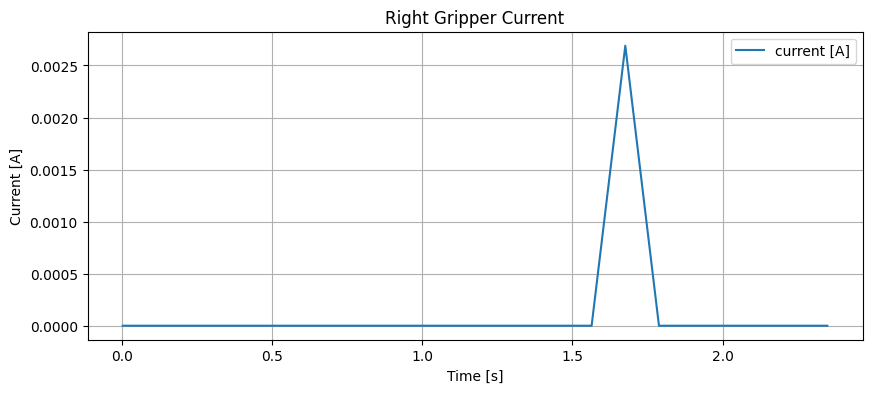

In [25]:
# 전류 모니터링
current_result = ysw.monitor_gripper_current(
    gripper=gripper,
    dxl_id=dxl_id,
    duration_sec=None,
    sample_dt=0.1,
    title="Right Gripper Current",
    verbose=False,
)

In [23]:
%matplotlib tk
current_result = ysw.monitor_gripper_current_live(
    gripper=gripper,
    dxl_id=dxl_id,
    duration_sec=None,          # Ctrl+C로 종료
    sample_dt=0.01,          
    title="Right Gripper Current",
    verbose=False,  
    ylim=(-0.1, 0.1),           # 필요 없으면 None  
    window_sec=None,            # 최근 10초만 보기. 전체 보려면 None
)

[INFO] Start current monitoring.
[INFO] Press Ctrl+C to stop.

[INFO] Current monitoring stopped by user.
[INFO] Current monitoring finished.
[INFO] Num samples: 157
Current mean     : 0.0007 A
Current max      : 0.0807 A
Current min      : -0.0753 A
Abs current max  : 0.0807 A


In [7]:
%matplotlib tk
position_result = ysw.monitor_gripper_live(
    gripper=gripper,
    dxl_id=dxl_id,
    signal="current",
    duration_sec=None,
    sample_dt=0.001,
    title="Right Gripper Current",
    verbose=False,
    ylim=(-0.1, 0.1),
    window_sec=None,
)

[INFO] Start current monitoring.
[INFO] Press Ctrl+C to stop.

[INFO] Current monitoring stopped by user.
[INFO] Gripper current monitoring finished.
[INFO] Num samples: 367
Current mean     : 0.0014 A
Current max      : 0.0081 A
Current min      : 0.0000 A


In [17]:
dxl_id = ysw.GRIPPER_ID_R

gripper = ysw.Gripper()
gripper.connect_hardCheck(
    device_name=ysw.GRIPPER_DEVICE_NAME, 
    protocol_version=ysw.DXL_PROTOCOL_VERSION, 
    baudrate=ysw.DXL_BAUDRATE,
    retry_interval=1.0,
    max_retry=5
)
gripper.test_ping()

gripper.initialize_setting(
    dxl_id=dxl_id, 
    operation_mode=ysw.DXL_CURRENT_BASED_POSITION_CONTROL_MODE, 
    Kp=ysw.DXL_P_GAIN_POSCTRL_YSW, 
    Ki=ysw.DXL_I_GAIN_POSCTRL_YSW,
    Kd=ysw.DXL_D_GAIN_POSCTRL_YSW
)

gripper.current_based_position_control_linear(ysw.GRIPPER_ID_R, current_ampere_mag=0.02, linear_pos=60.0)

%matplotlib tk
position_result = ysw.monitor_gripper_live(
    gripper=gripper,
    dxl_id=dxl_id,
    signal="position",
    duration_sec=None,
    sample_dt=0.001,
    title="Right Gripper Position",
    verbose=False,
    ylim=(0, 100),
    window_sec=None,
)

*********************** [Gripper Hard Connection Starts] ***********************

[Gripper] Trying to connect gripper... attempt=1
************************* [Gripper Connection Starts] **************************

[INFO] SUCCESS: open the port: /dev/rby1_gripper
[INFO] SUCCESS: change the baudrate 2000000

************************* [Gripper Connection is Done] *************************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

************************* [Gripper Ping Test is Done] **************************



[Gripper] connect=True, ping_test=True

********************** [Gripper Hard Connection is Done] ***********************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

***

<span style="
    color:#B8860B;
    font-family:'Segoe UI', 'Arial', sans-serif;
    font-weight:700;
    font-size:30px;
    letter-spacing:1px;
    line-height:1.2;
">
Step Response Test [Position]
</span>

*********************** [Gripper Hard Connection Starts] ***********************

[Gripper] Trying to connect gripper... attempt=1
************************* [Gripper Connection Starts] **************************

[INFO] SUCCESS: open the port: /dev/rby1_gripper
[INFO] SUCCESS: change the baudrate 2000000

************************* [Gripper Connection is Done] *************************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

************************* [Gripper Ping Test is Done] **************************



[Gripper] connect=True, ping_test=True

********************** [Gripper Hard Connection is Done] ***********************



************************** [Gripper Ping Test Starts] **************************

[INFO] [DXL ID:0] SUCCESS: Dynamixel model number is 1030
[INFO] [DXL ID:1] SUCCESS: Dynamixel model number is 1030

***

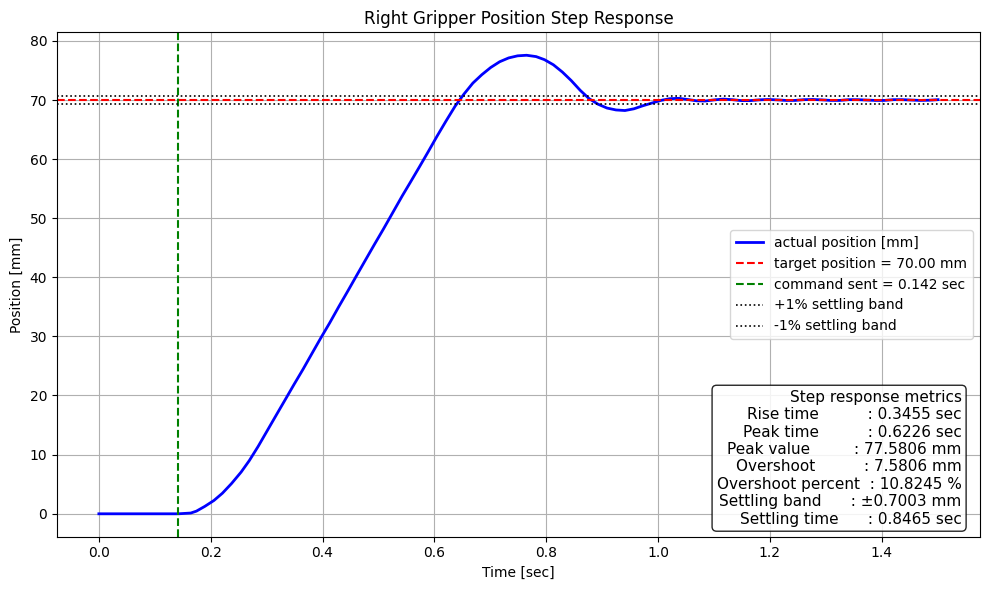

********************* [Gripper [DXL ID:0] Disable Starts] **********************

[INFO] SUCCESS: [DXL ID:0] Torque is Disabled

********************* [Gripper [DXL ID:0] Disable is Done] *********************





True

In [ ]:
# Select
dxl_id = ysw.GRIPPER_ID_R

gripper = ysw.Gripper()
gripper.connect_hardCheck(
    device_name=ysw.GRIPPER_DEVICE_NAME, 
    protocol_version=ysw.DXL_PROTOCOL_VERSION, 
    baudrate=ysw.DXL_BAUDRATE,
    retry_interval=1.0,
    max_retry=5,
)
gripper.test_ping()

gripper.initialize_setting(
    dxl_id=dxl_id, 
    operation_mode=ysw.DXL_CURRENT_BASED_POSITION_CONTROL_MODE, 
    Kp=ysw.DXL_P_GAIN_POSCTRL_YSW, 
    Ki=ysw.DXL_I_GAIN_POSCTRL_YSW,
    Kd=ysw.DXL_D_GAIN_POSCTRL_YSW,
)

result = ysw.record_response_for_stepPositionReference(
    gripper=gripper,
    dxl_id=ysw.GRIPPER_ID_R,
    target_pos_mm=70.0,
    current_ampere_mag=0.1,
    pre_record_sec=0.1,
    sample_dt=0.01,
    settled_time=0.5,
    timeout_sec=8.0,
    title="Right Gripper Position Step Response",
    plot=True,
)

gripper.disable(dxl_id=dxl_id)